In [ ]:
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from matplotlib.ticker import MaxNLocator

In [ ]:
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", None)
data = pd.read_csv("/content/drive/MyDrive/nmt_results.csv",sep=",")
df = pd.DataFrame(data)
print(df)

           block3 block3ball100   tertypename                     eotypename  \
0      Математика         152,0         місто                          ліцей   
1      Математика         172,0         місто                          ліцей   
2      Математика         200,0         місто                          ліцей   
3      Математика         125,0         місто                          ліцей   
4      Математика         142,0         місто                          ліцей   
...           ...           ...           ...                            ...   
31440  Математика         108,0         місто                          ліцей   
31441  Математика         108,0         місто                          ліцей   
31442  Математика         123,0  селище, село  середня загальноосвітня школа   
31443  Математика         167,0         місто                          ліцей   
31444  Математика         134,0         місто                          ліцей   

      sextypename  year  
0          жі

In [ ]:
print(df.eotypename.value_counts(dropna=False))

eotypename
ліцей                                                11673
середня загальноосвітня школа                         6292
NaN                                                   5267
заклад фахової передвищої освіти                      4125
гімназія                                              1462
заклад професійної (професійно-технічної) освіти       715
ліцей із посиленою військово-фізичною підготовкою      530
спеціалізована школа                                   427
навчально-виховний комплекс                            387
науковий ліцей                                         374
колегіум/колеж                                         158
спеціальна школа                                        16
навчально-реабілітаційний центр                         10
Пенітенціарна установа                                   5
спеціальна загальноосвітня школа                         4
Name: count, dtype: int64


In [ ]:
categories_map = {
    'середня загальноосвітня школа': 'Загальноосвітня школа',
    'гімназія': 'Загальноосвітня школа',

    'ліцей': 'Ліцей',
    'ліцей із посиленою військово-фізичною підготовкою': 'Ліцей',
    'науковий ліцей': 'Ліцей',

    'заклад фахової передвищої освіти': 'Коледж / Профтех',
    'заклад професійної (професійно-технічної) освіти': 'Коледж / Профтех',
    'колегіум/колеж': 'Коледж / Профтех',

    'спеціалізована школа': 'Спеціальні заклади / Інше',
    'навчально-виховний комплекс': 'Спеціальні заклади / Інше',
    'спеціальна школа': 'Спеціальні заклади / Інше',
    'навчально-реабілітаційний центр': 'Спеціальні заклади / Інше',
    'Пенітенціарна установа': 'Спеціальні заклади / Інше',
    'спеціальна загальноосвітня школа': 'Спеціальні заклади / Інше',
}

In [ ]:
df['school_type'] = df['eotypename'].map(categories_map)
df['school_type'] = df['school_type'].fillna('Невідомі дані')

print(df['school_type'].value_counts())

school_type
Ліцей                        12577
Загальноосвітня школа         7754
Невідомі дані                 5267
Коледж / Профтех              4998
Спеціальні заклади / Інше      849
Name: count, dtype: int64


In [ ]:
df['block3ball100'] = df['block3ball100'].str.replace(",", ".")
df['block3ball100'] = df['block3ball100'].astype(float)
df['year'] = df['year'].astype(int)
print(df.groupby('sextypename')['block3ball100'].agg(
    Кількість='count',
    Середнє='mean',
    Медіана='median',
    Стандартне_відхилення='std'
).round(2))

             Кількість  Середнє  Медіана  Стандартне_відхилення
sextypename                                                    
жіноча           16067   134.89    134.0                  20.81
чоловіча         15378   133.99    134.0                  21.31


In [ ]:
print(df.groupby('school_type')['block3ball100'].agg(
    Кількість='count',
    Середнє='mean',
    Медіана='median',
    Стандартне_відхилення='std'
).round(2))

                           Кількість  Середнє  Медіана  Стандартне_відхилення
school_type                                                                  
Загальноосвітня школа           7754   138.38    138.0                  21.23
Коледж / Профтех                4998   127.78    131.0                  17.41
Ліцей                          12577   137.69    137.0                  21.95
Невідомі дані                   5267   125.74    126.0                  16.87
Спеціальні заклади / Інше        849   143.69    144.0                  22.67


In [ ]:
print(df.groupby('tertypename')['block3ball100'].agg(
    Кількість='count',
    Середнє='mean',
    Медіана='median',
    Стандартне_відхилення='std'
).round(2))

                      Кількість  Середнє  Медіана  Стандартне_відхилення
tertypename                                                             
місто                     23545   135.53    136.0                  21.40
селище міського типу       1451   139.29    138.0                  20.26
селище, село               6449   129.38    131.0                  19.04


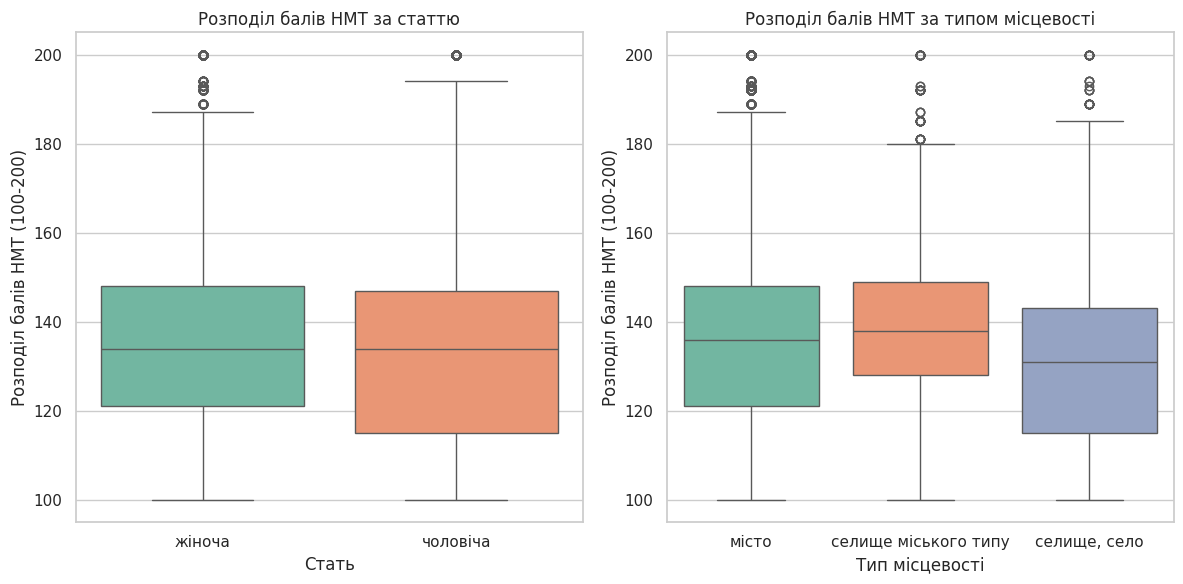

In [ ]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1,2, figsize=(12,6))

sns.boxplot(ax=axes[0], data=df,x=df['sextypename'], y=df['block3ball100'], hue=df['sextypename'], palette="Set2", legend=False)
axes[0].set_title('Розподіл балів НМТ за статтю')
axes[0].set_xlabel('Стать')
axes[0].set_ylabel('Розподіл балів НМТ (100-200)')

sns.boxplot(ax=axes[1], data=df,x=df['tertypename'], y=df['block3ball100'], hue=df['tertypename'], palette="Set2", legend=False)
axes[1].set_title('Розподіл балів НМТ за типом місцевості')
axes[1].set_xlabel('Тип місцевості')
axes[1].set_ylabel('Розподіл балів НМТ (100-200)')

plt.tight_layout()
plt.show()

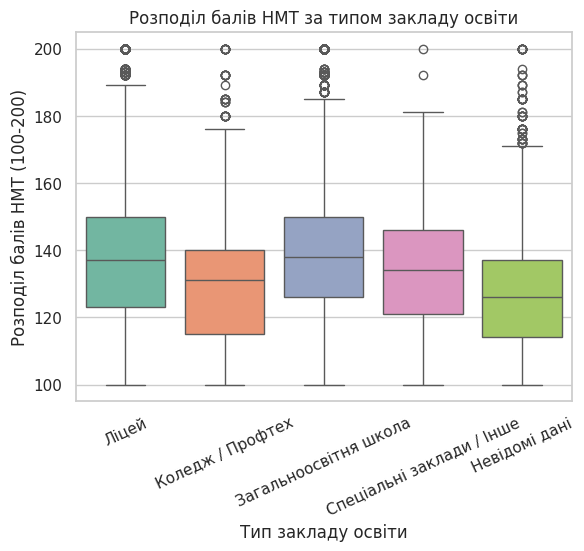

In [ ]:
sns.set_theme(style="whitegrid")
sns.boxplot(data=df,x=df['school_type'], y=df['block3ball100'], hue=df['school_type'], palette="Set2", legend=False)
plt.title('Розподіл балів НМТ за типом закладу освіти')
plt.xlabel('Тип закладу освіти')
plt.tick_params(axis='x', rotation=25)
plt.ylabel('Розподіл балів НМТ (100-200)')
plt.show()

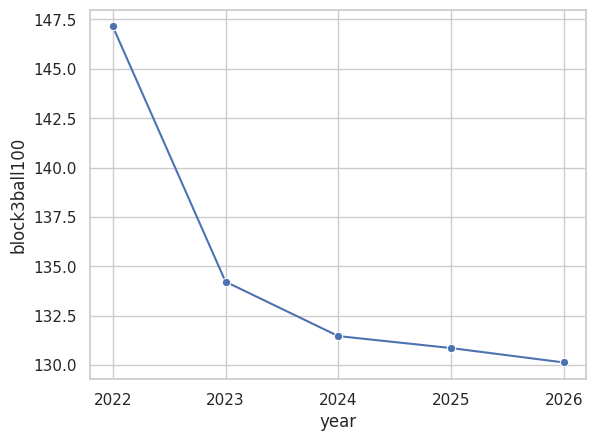

In [ ]:
year_avg = df.groupby('year', as_index=False)['block3ball100'].mean()

sns.lineplot(data=year_avg, x='year', y='block3ball100', marker='o')
plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))
plt.show()

ml частина

In [ ]:
import numpy as np
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error,r2_score
from sklearn.model_selection import train_test_split

In [ ]:
X = df.drop(['block3', 'block3ball100','eotypename', 'year'], axis=1)
y = df['block3ball100']

In [ ]:
X_encoded = pd.get_dummies(X)
X_encoded

,tertypename_місто,tertypename_селище міського типу,"tertypename_селище, село",sextypename_жіноча,sextypename_чоловіча,school_type_Загальноосвітня школа,school_type_Коледж / Профтех,school_type_Ліцей,school_type_Невідомі дані,school_type_Спеціальні заклади / Інше
0,True,False,False,True,False,False,False,True,False,False
1,True,False,False,False,True,False,False,True,False,False
2,True,False,False,True,False,False,False,True,False,False
3,True,False,False,False,True,False,False,True,False,False
4,True,False,False,True,False,False,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...
31440,True,False,False,False,True,False,False,True,False,False
31441,True,False,False,False,True,False,False,True,False,False
31442,False,False,True,True,False,True,False,False,False,False
31443,True,False,False,True,False,False,False,True,False,False


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42
)

In [ ]:
random_forest_model = RandomForestRegressor(n_estimators=100, random_state=42)
random_forest_model.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [ ]:
y_pred = random_forest_model.predict(X_test)
y_pred

array([129.47814987, 141.80455988, 124.41999264, ..., 140.78188512,
       140.78188512, 145.13868234])

In [ ]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Результати ML-моделі")
print("Коефіцієнт детермінації: ", r2)
print("Середня абсолютна похибка  (MAE): ", mae)
print("Квадратична помилка (RMSE): ", rmse)

Результати ML-моделі
Коефіцієнт детермінації:  0.1140533318551663
Середня абсолютна похибка  (MAE):  15.78497380965486
Квадратична помилка (RMSE):  19.82467050085155


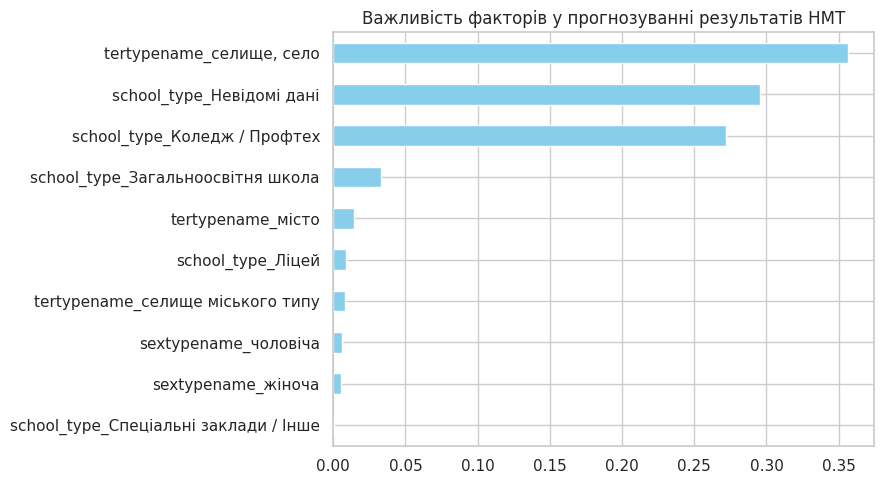

In [ ]:
importances = pd.Series(random_forest_model.feature_importances_, index=X_encoded.columns).sort_values()

plt.figure(figsize=(9, 5))
importances.plot(kind='barh', color='skyblue')
plt.title("Важливість факторів у прогнозуванні результатів НМТ")
plt.tight_layout()
plt.show()
